# 📊 Water Quality Dataset - Exploratory Data Analysis

**Author:** M.Tech Project Team  
**Date:** March 2026  
**Purpose:** Comprehensive analysis of water quality dataset for IEEE paper

---

## 📋 Contents
1. Dataset Overview
2. Statistical Summary
3. Distribution Analysis
4. Correlation Analysis
5. Missing Value Analysis
6. Class Balance
7. Key Insights

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set style for publication-quality plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("✓ Libraries imported successfully")

✓ Libraries imported successfully


## 1️⃣ Dataset Overview

In [2]:
# Load dataset
data_path = Path('../data/raw/water_potability.csv')
df = pd.read_csv(data_path)

print("📊 DATASET OVERVIEW")
print("=" * 70)
print(f"Total Samples: {len(df):,}")
print(f"Features: {len(df.columns) - 1}")
print(f"Target: Potability (0=Not Potable, 1=Potable)")
print("\nFirst 5 rows:")
df.head()

📊 DATASET OVERVIEW
Total Samples: 3,276
Features: 9
Target: Potability (0=Not Potable, 1=Potable)

First 5 rows:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [3]:
# Dataset info
print("\n📋 DATASET INFORMATION")
print("=" * 70)
df.info()


📋 DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


## 2️⃣ Statistical Summary

In [4]:
# Comprehensive statistics
print("\n📈 STATISTICAL SUMMARY")
print("=" * 70)
summary = df.describe().T
summary['missing'] = df.isnull().sum()
summary['missing_pct'] = (df.isnull().sum() / len(df) * 100).round(2)
summary


📈 STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max,missing,missing_pct
ph,2785.0,7.080795,1.594320,0.000000,6.093092,7.036752,8.062066,14.000000,491,14.99
Hardness,3276.0,196.369496,32.879761,47.432000,176.850538,196.967627,216.667456,323.124000,0,0.00
Solids,3276.0,22014.092526,8768.570828,320.942611,15666.690297,20927.833607,27332.762127,61227.196008,0,0.00
Chloramines,3276.0,7.122277,1.583085,0.352000,6.127421,7.130299,8.114887,13.127000,0,0.00
Sulfate,2495.0,333.775777,41.416840,129.000000,307.699498,333.073546,359.950170,481.030642,781,23.84
Conductivity,3276.0,426.205111,80.824064,181.483754,365.734414,421.884968,481.792304,753.342620,0,0.00
Organic_carbon,3276.0,14.284970,3.308162,2.200000,12.065801,14.218338,16.557652,28.300000,0,0.00
Trihalomethanes,3114.0,66.396293,16.175008,0.738000,55.844536,66.622485,77.337473,124.000000,162,4.95
Turbidity,3276.0,3.966786,0.780382,1.450000,3.439711,3.955028,4.500320,6.739000,0,0.00
Potability,3276.0,0.390110,0.487849,0.000000,0.000000,0.000000,1.000000,1.000000,0,0.00


## 3️⃣ Distribution Analysis

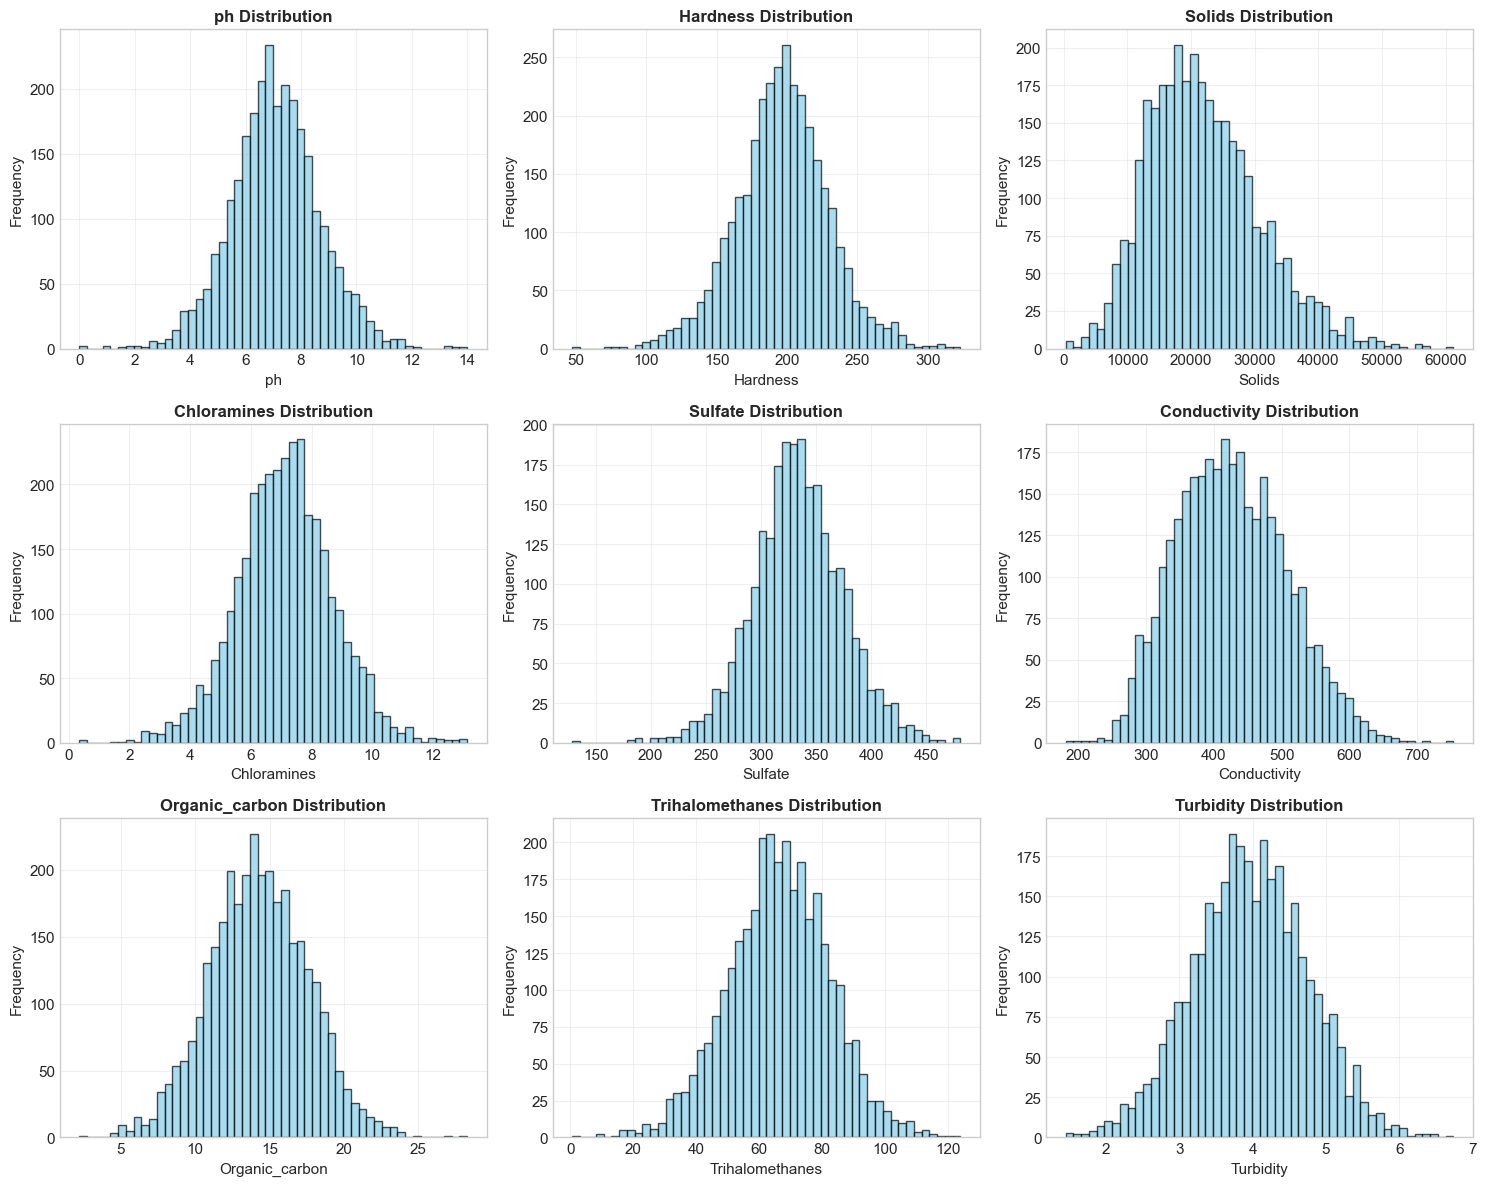

✓ Distribution plots saved to outputs/plots/eda/


In [5]:
# Feature distributions
features = [col for col in df.columns if col != 'Potability']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for idx, feature in enumerate(features):
    axes[idx].hist(df[feature].dropna(), bins=50, color='skyblue', edgecolor='black', alpha=0.7)
    axes[idx].set_title(f'{feature} Distribution', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(feature)
    axes[idx].set_ylabel('Frequency')
    axes[idx].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../outputs/jupiter/plots/eda/feature_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Distribution plots saved to outputs/plots/eda/")

## 4️⃣ Correlation Analysis

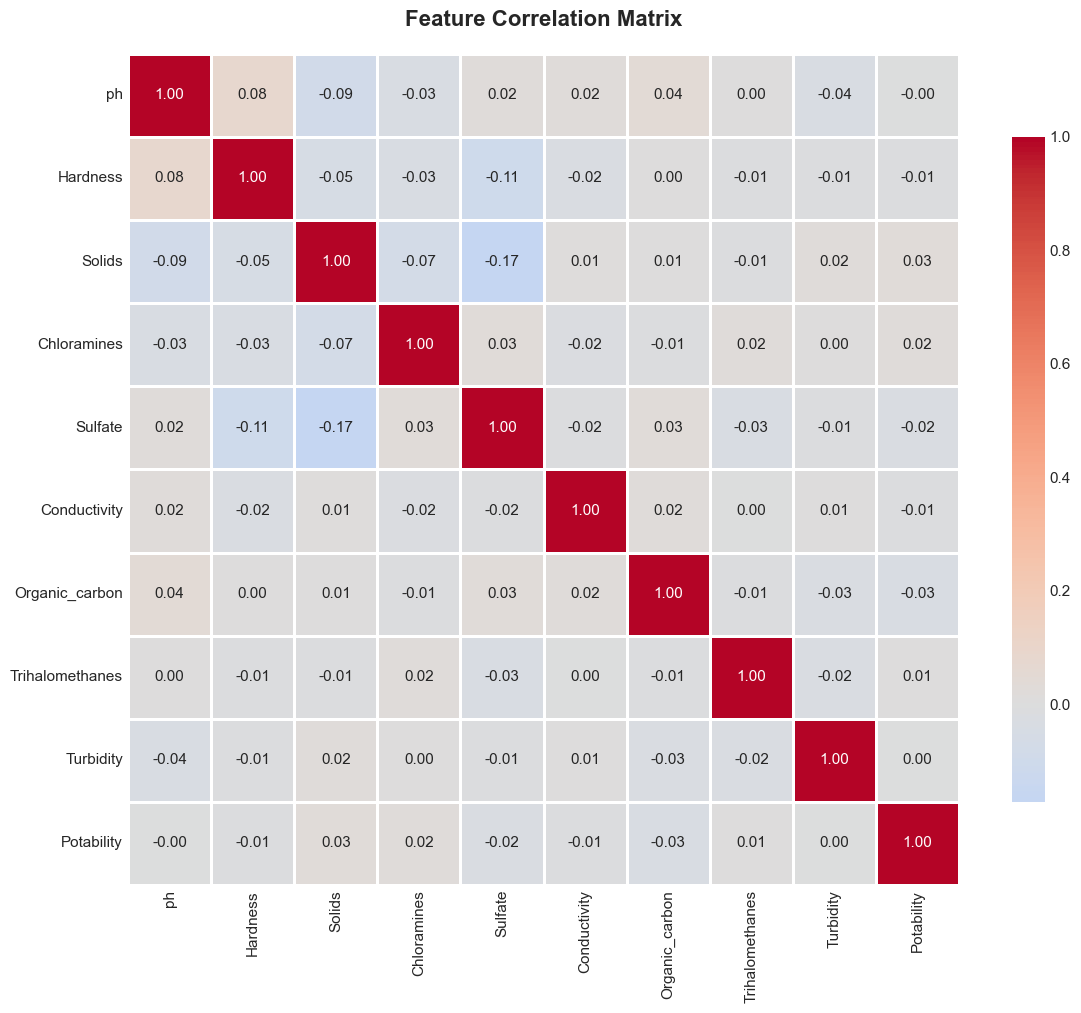


🔍 STRONGEST CORRELATIONS WITH POTABILITY
Solids             0.033743
Chloramines        0.023779
Trihalomethanes    0.007130
Turbidity          0.001581
ph                -0.003556
Conductivity      -0.008128
Hardness          -0.013837
Sulfate           -0.023577
Organic_carbon    -0.030001
Name: Potability, dtype: float64


In [6]:
# Correlation heatmap
plt.figure(figsize=(12, 10))
correlation = df.corr()

sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})

plt.title('Feature Correlation Matrix', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('../outputs/jupiter/plots/eda/correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n🔍 STRONGEST CORRELATIONS WITH POTABILITY")
print("=" * 70)
potability_corr = correlation['Potability'].drop('Potability').sort_values(ascending=False)
print(potability_corr)

## 5️⃣ Missing Value Analysis

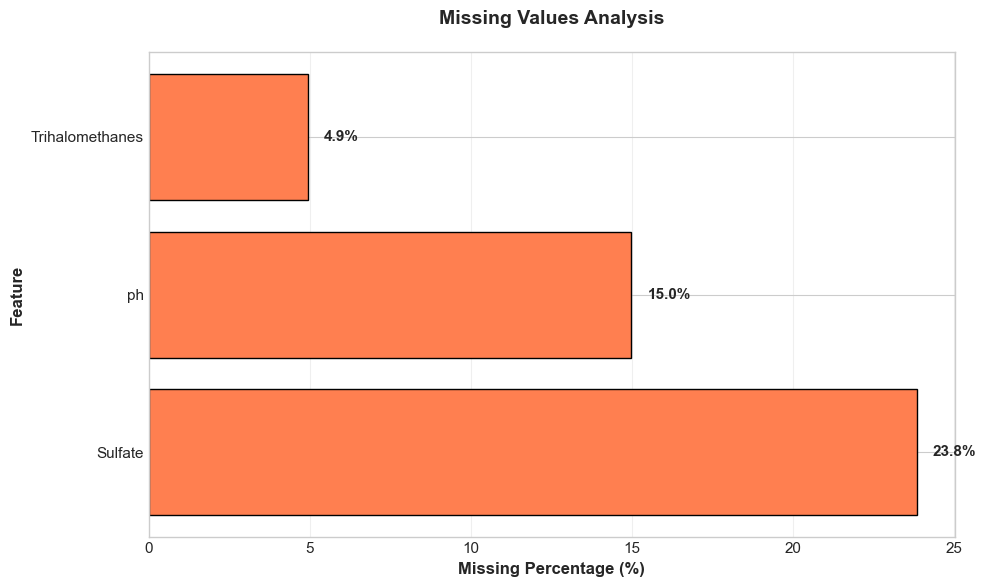


⚠️ MISSING VALUES SUMMARY
        Feature  Missing Count  Missing %
        Sulfate            781  23.840049
             ph            491  14.987790
Trihalomethanes            162   4.945055


In [7]:
# Missing values visualization
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100)
missing_df = pd.DataFrame({
    'Feature': missing.index,
    'Missing Count': missing.values,
    'Missing %': missing_pct.values
})

missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)

if len(missing_df) > 0:
    plt.figure(figsize=(10, 6))
    bars = plt.barh(missing_df['Feature'], missing_df['Missing %'], color='coral', edgecolor='black')
    
    for i, bar in enumerate(bars):
        width = bar.get_width()
        plt.text(width + 0.5, bar.get_y() + bar.get_height()/2, 
                f'{width:.1f}%', ha='left', va='center', fontweight='bold')
    
    plt.xlabel('Missing Percentage (%)', fontsize=12, fontweight='bold')
    plt.ylabel('Feature', fontsize=12, fontweight='bold')
    plt.title('Missing Values Analysis', fontsize=14, fontweight='bold', pad=20)
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.savefig('../outputs/jupiter/plots/eda/missing_values.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\n⚠️ MISSING VALUES SUMMARY")
    print("=" * 70)
    print(missing_df.to_string(index=False))
else:
    print("✓ No missing values found!")

## 6️⃣ Class Balance Analysis

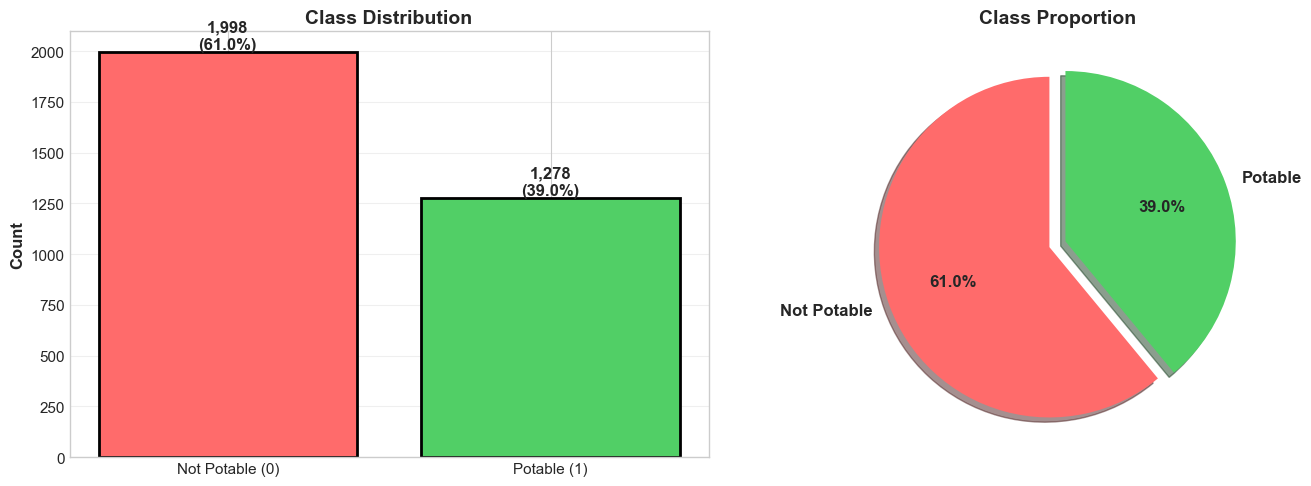


⚖️ CLASS BALANCE
Not Potable (0): 1,998 (60.99%)
Potable (1):     1,278 (39.01%)

Imbalance Ratio: 1.56:1


In [8]:
# Class distribution
class_counts = df['Potability'].value_counts()
class_pct = df['Potability'].value_counts(normalize=True) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot
colors = ['#ff6b6b', '#51cf66']
bars = ax1.bar(['Not Potable (0)', 'Potable (1)'], class_counts.values, 
               color=colors, edgecolor='black', linewidth=2)

for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height):,}\n({height/len(df)*100:.1f}%)',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

ax1.set_ylabel('Count', fontsize=12, fontweight='bold')
ax1.set_title('Class Distribution', fontsize=14, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)

# Pie chart
ax2.pie(class_counts.values, labels=['Not Potable', 'Potable'], 
        autopct='%1.1f%%', colors=colors, startangle=90,
        explode=(0.05, 0.05), shadow=True, textprops={'fontsize': 12, 'fontweight': 'bold'})
ax2.set_title('Class Proportion', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../outputs/jupiter/plots/eda/class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n⚖️ CLASS BALANCE")
print("=" * 70)
print(f"Not Potable (0): {class_counts[0]:,} ({class_pct[0]:.2f}%)")
print(f"Potable (1):     {class_counts[1]:,} ({class_pct[1]:.2f}%)")
print(f"\nImbalance Ratio: {class_counts[0]/class_counts[1]:.2f}:1")

## 7️⃣ Key Insights for IEEE Paper

In [10]:
print("\n📝 KEY INSIGHTS FOR IEEE PAPER")
print("=" * 70)

insights = f"""
1. DATASET CHARACTERISTICS:
   • Total samples: {len(df):,}
   • Features: {len(features)} physicochemical parameters
   • Class imbalance: {class_counts[0]/class_counts[1]:.2f}:1 (requires handling)

2. DATA QUALITY:
   • Missing values present in {len(missing_df)} features
   • Requires imputation strategy for robust modeling

3. FEATURE CORRELATIONS:
   • Low correlation with target (max: {abs(potability_corr).max():.3f})
   • Suggests complex non-linear relationships
   • Justifies use of ensemble ML methods

4. DISTRIBUTION PATTERNS:
   • Most features show normal/near-normal distributions
   • Some outliers present (typical for real-world sensor data)

5. IMPLICATIONS FOR MODELING:
   • Class balancing required (SMOTE/class weights)
   • Feature scaling necessary
   • Ensemble methods preferred over linear models
   • Cross-validation essential for robust evaluation
"""

print(insights)

# Save insights
with open('../outputs/jupiter/eda_insights.txt', 'w') as f:
    f.write(insights)

print("\n✓ Insights saved to outputs/jupiter/eda_insights.txt")


📝 KEY INSIGHTS FOR IEEE PAPER

1. DATASET CHARACTERISTICS:
   • Total samples: 3,276
   • Features: 9 physicochemical parameters
   • Class imbalance: 1.56:1 (requires handling)

2. DATA QUALITY:
   • Missing values present in 3 features
   • Requires imputation strategy for robust modeling

3. FEATURE CORRELATIONS:
   • Low correlation with target (max: 0.034)
   • Suggests complex non-linear relationships
   • Justifies use of ensemble ML methods

4. DISTRIBUTION PATTERNS:
   • Most features show normal/near-normal distributions
   • Some outliers present (typical for real-world sensor data)

5. IMPLICATIONS FOR MODELING:
   • Class balancing required (SMOTE/class weights)
   • Feature scaling necessary
   • Ensemble methods preferred over linear models
   • Cross-validation essential for robust evaluation


✓ Insights saved to outputs/jupiter/eda_insights.txt


---

## 🎯 Summary

This exploratory analysis reveals:
- **Dataset size**: 3,276 samples with 9 features
- **Challenge**: Class imbalance and missing values
- **Opportunity**: Complex patterns suitable for ML
- **Recommendation**: Ensemble methods with preprocessing

**Next Steps**: Proceed to classification analysis (Notebook 02)